<a href="https://colab.research.google.com/github/ziaahmedf17/AiImageGenerator/blob/main/Lab_8_EDA%2BML_using_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EDA + ML using LLM**
* ChatGPT LLM
* Scikit LLM


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Code: df['Age'].hist()
Result: Axes(0.125,0.11;0.775x0.77)


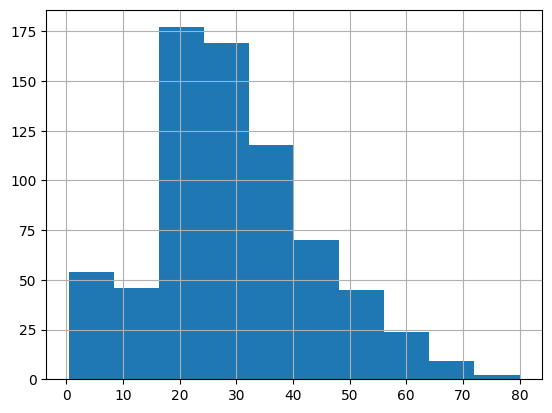

In [2]:
import pandas as pd
from openai import OpenAI
from google.colab import userdata

# 1. Setup Data & Client (uses OPENAI_API_KEY from environment/Colab Secrets)
#df = pd.DataFrame([
    #('John Doe', 25, 50), ('Jane Smith', 38, 70),
    #('Alex Johnson', 45, 80), ('Jessica Brown', 60, 40),
    #('Michael Davis', 22, 90), ('Emily Wilson', 30, 60),
    #('Daniel Taylor', 35, 75), ('Sophia Moore', 40, 85),
    #('David Thomas', 50, 65), ('Olivia Jackson', 29, 55)
#], columns=['name', 'age', 'donation'])
# /content/drive/MyDrive/COLAB/Lab_7_Machine_Learning_Implementation/heart_2022_with_nans.csv
df = pd.read_csv("/content/drive/MyDrive/COLAB/Lab_7_Machine_Learning_Implementation/Titanic.csv")

# Fetching key securely from Colab Secrets
api_key = userdata.get('OpenAiKey')

client = OpenAI(api_key=api_key)

# 2. Ask OpenAI for the pandas expression
#question = "What is the average donation of people older than 40 who donated more than $50?"
question = "Create histogram for the age feature"
res = client.responses.create(
    model="gpt-4.1-mini",
    instructions="Return ONLY a single-line Python pandas expression using `df` (no markdown, no variable assignment).",
    input=f"Columns: {list(df.columns)}\nQuestion: {question}"
)

# 3. Evaluate and print
code = res.output_text.strip()
print(f"Code: {code}\nResult: {eval(code)}")

In [5]:
!pip install -q google-genai

In [13]:
import pandas as pd
from google import genai
from google.colab import userdata

# 1. Load Titanic dataset
df = pd.read_csv("/content/drive/MyDrive/COLAB/Lab_7_Machine_Learning_Implementation/Titanic.csv")

# 3. Initialize Gemini client
client = genai.Client(api_key=userdata.get('GeminiKey'))

# 4. Define natural-language question
question = "Create histogram for the age feature"

# 5. Ask Gemini to generate a Pandas expression
res = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=f"""
    Return ONLY a single-line Python pandas expression
    using `df`. Do not include markdown or variable assignment.

    Columns: {list(df.columns)}
    Question: {question}
    """
)

# 6. Extract generated expression
code = res.text.strip()

print("Generated Pandas expression:")
print(code)

# 7. Execute and display result
result = eval(code, {"df": df})

print("\nResult:")
print(result)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [4]:
!pip install -q anthropic

Generated code: df['Age'].plot(kind='hist', title='Age Distribution', xlabel='Age', ylabel='Frequency')
Result: Axes(0.125,0.11;0.775x0.77)


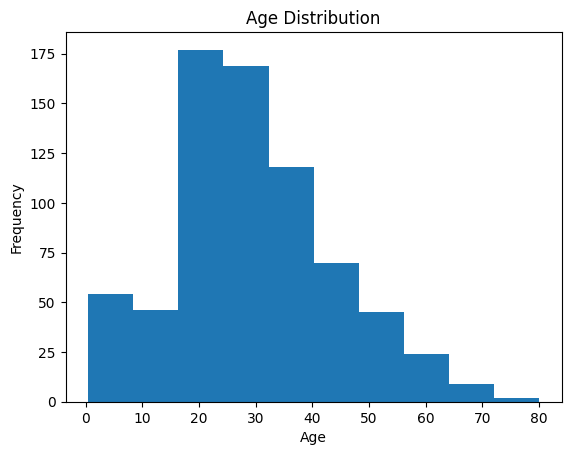

In [14]:

import pandas as pd
from anthropic import Anthropic

df = pd.read_csv("/content/drive/MyDrive/COLAB/Lab_7_Machine_Learning_Implementation/Titanic.csv")

client = Anthropic(api_key=userdata.get('Anthropic'))

question = "Create histogram for the age feature"

res = client.messages.create(
    model="claude-sonnet-4-6",
    max_tokens=300,
    messages=[
        {
            "role": "user",
            "content": f"Generate only a Python pandas expression using df. Columns: {list(df.columns)}. Do not include markdown or variable assignment. Question: {question}"
        }
    ]
)

code = res.content[0].text.strip()
print("Generated code:", code)

# Remove Markdown code fences if generated
# code = code.replace("```python", "").replace("```", "").strip()

result = eval(code, {"df": df})
print("Result:", result)


# Lab Task

* Get your OpenAI and Gemini API keys, and execute the above code.
* Modify the prompt and analyze the LLM's responses to various prompts.
* Apply EDA using an LLM on the following dataset.

https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease

* Explore how we can use ScikitLLM for making predictions.
* Exlpore the PandasAI library (https://pypi.org/project/pandasai/) and determine how it is more convinient than using individual LLM libraries.  
* Develop a Streamlit-based frontend that allows users to upload datasets and ask questions about the uploaded data.

Using PandasAi

In [18]:
%%bash
pip install -q pandasai --only-binary=:all:

/content/exports/charts/temp_chart.png


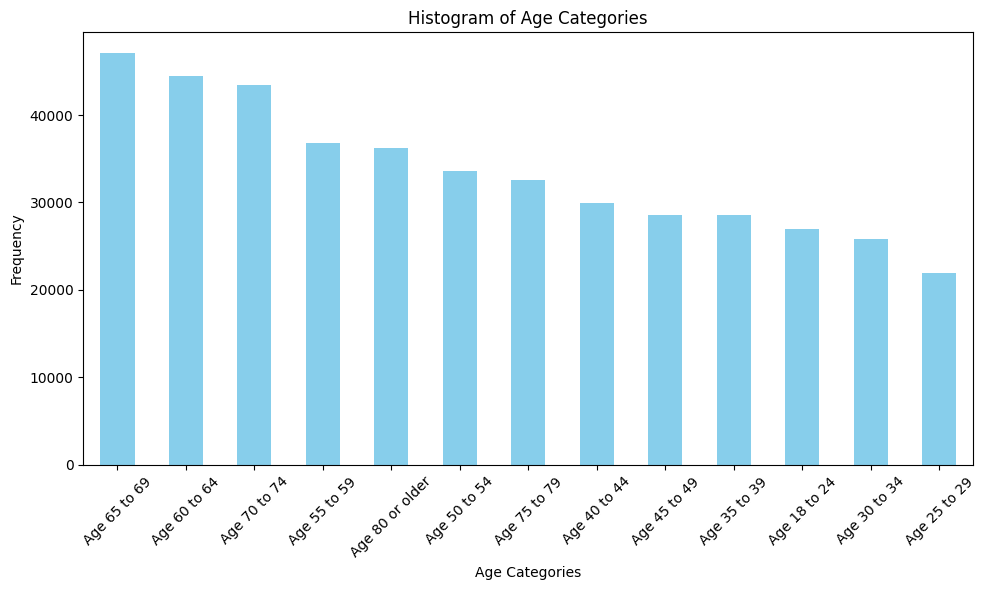

In [37]:
import pandas as pd
from pandasai import SmartDataframe
from google.colab import userdata
from pandasai.llm import OpenAI

# 1. Load the dataset
df = pd.read_csv("/content/drive/MyDrive/COLAB/Lab_7_Machine_Learning_Implementation/heart_2022_with_nans.csv")

# 2. Get API key from secrets
openai_api_key = userdata.get('OpenAiKey')

# 3. Create a Custom LLM class that inherits correctly
class UnvalidatedOpenAI(OpenAI):
    def __init__(self, api_token: str, model: str = "gpt-4o-mini", **kwargs):
        # Temporarily bypass validation block by defining gpt-4o-mini as valid on the class level
        super().__init__(api_token=api_token, model="gpt-4", **kwargs)
        # Force switch the target model back to gpt-4o-mini after valid initialization
        self.model = model

# Initialize with our workaround OpenAI wrapper
llm = UnvalidatedOpenAI(api_token=openai_api_key)

# 4. Instantiate SmartDataframe
smart_df = SmartDataframe(df, config={"llm": llm})

# 5. Ask questions / Perform EDA
response = smart_df.chat("Create a histogram for the age feature")
print(response)

Prediction using ScikitLM

In [38]:
%%bash
pip install -q scikit-llm

In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from skllm.config import SKLLMConfig
# Correct import path for newer Scikit-LLM v0.2+ versions
from skllm.models.gpt.classification.zero_shot import ZeroShotGPTClassifier
from google.colab import userdata

# 1. Securely set the API key for Scikit-LLM
api_key = userdata.get('OpenAiKey')
SKLLMConfig.set_openai_key(api_key)

# 2. Load the dataset (Titanic dataset as an example)
df_titanic = pd.read_csv("/content/drive/MyDrive/COLAB/Lab_7_Machine_Learning_Implementation/Titanic.csv")

# For text-based classification with LLMs, let's create a textual representation from features to predict 'Survived'
# We will drop rows where key features are missing for demonstration
df_cleaned = df_titanic.dropna(subset=['Pclass', 'Sex', 'Age', 'Survived']).copy()

# Map Survived numeric target to descriptive labels
df_cleaned['Survived_Label'] = df_cleaned['Survived'].map({0: 'did not survive', 1: 'survived'})

# Construct a descriptive text profile for each passenger
df_cleaned['profile'] = df_cleaned.apply(
    lambda row: f"A {row['Sex']} passenger of age {row['Age']} traveling in class {row['Pclass']}.",
    axis=1
)

X = df_cleaned['profile'].values
y = df_cleaned['Survived_Label'].values

# 3. Split into Train & Test (using a small subset to conserve tokens and speed up API calls)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=10, random_state=42, stratify=y)

# 4. Initialize and fit the ZeroShotGPTClassifier
# We will use gpt-4o-mini as our underlying prediction engine
clf = ZeroShotGPTClassifier(model="gpt-4o-mini")
clf.fit(X_train, y_train)

# 5. Predict and evaluate
predictions = clf.predict(X_test)

print("--- Predictions on Test Set ---")
for prof, true_lbl, pred_lbl in zip(X_test, y_test, predictions):
    print(f"Profile: {prof}")
    print(f"Actual: {true_lbl} | Predicted: {pred_lbl}\n")

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:\n", classification_report(y_test, predictions))

100%|██████████| 10/10 [00:07<00:00,  1.30it/s]

--- Predictions on Test Set ---
Profile: A male passenger of age 28.0 traveling in class 3.
Actual: did not survive | Predicted: did not survive

Profile: A female passenger of age 48.0 traveling in class 3.
Actual: did not survive | Predicted: survived

Profile: A male passenger of age 23.0 traveling in class 2.
Actual: did not survive | Predicted: survived

Profile: A male passenger of age 36.0 traveling in class 3.
Actual: did not survive | Predicted: did not survive

Profile: A female passenger of age 35.0 traveling in class 2.
Actual: survived | Predicted: survived

Profile: A male passenger of age 19.0 traveling in class 3.
Actual: did not survive | Predicted: did not survive

Profile: A male passenger of age 36.0 traveling in class 1.
Actual: did not survive | Predicted: survived

Profile: A male passenger of age 21.0 traveling in class 3.
Actual: survived | Predicted: did not survive

Profile: A male passenger of age 35.0 traveling in class 1.
Actual: survived | Predicted: surv